In [1]:
from IPython.display import Image, display
import os
from dotenv import load_dotenv
load_dotenv()
for variable in (
    "LANGCHAIN_TRACING",
    "LANGCHAIN_TRACING_V2",
    "LANGSMITH_TRACING",
    "LANGSMITH_TRACING_V2",
):
    os.environ[variable] = "false"

import glob, operator
from pydantic import BaseModel, Field
from langchain_openai import ChatOpenAI
from typing import Annotated, Literal, TypedDict
from langgraph.graph import StateGraph, START, END

class Requirement(BaseModel):
    name: str = Field(description="The name of the requirement")
    description: str = Field(description="A detailed description of the requirement")
class ExtractionResult(BaseModel):
    requirements: list[Requirement]

class State(TypedDict):
    input_dir: str
    docs: dict[str, str]
    raw_reqs: list[dict]
    merged_reqs: list[dict]
    blacklist: Annotated[list[dict], operator.add]
    kept_reqs: list[dict]
    review_missing: dict[str, list[str]]
    iterations: int

class DeduplicateGroup(BaseModel):
    ids: list[int] = Field(description="Numbers of the requirements that mean the same thing. Single-item list if unique.")
    name: str = Field(description="Short descriptive name for the merged requirement")
    description: str = Field(description="One paragraph combining the details of all grouped items")

class DedupResult(BaseModel):
    groups: list[DeduplicateGroup]

class Discard(BaseModel):
    id: int = Field(description='Id of the requirement to discard')
    reason: str = Field(description='Why it is discarded (conflict, nonsensical, out of scope)')
    conflicts_with: list[int] = Field(default_factory=list, description="Numbers of conflicting requirements that are kept")
class ConflictResult(BaseModel):
    discards: list[Discard]

class Priority(BaseModel):
    id: int = Field(description='id of the requirement to assign priority to')
    justification: str = Field(description='Short reason for why such priority was assigned')
    priority: Literal["Top","High","Mid","Low"]
class PriorityResult(BaseModel):
    priorities: list[Priority]

class MissingItem(BaseModel):
    requirement: str = Field(description="A requirement in the document that the list does not cover")
class ReviewResult(BaseModel):
    missing: list[MissingItem]


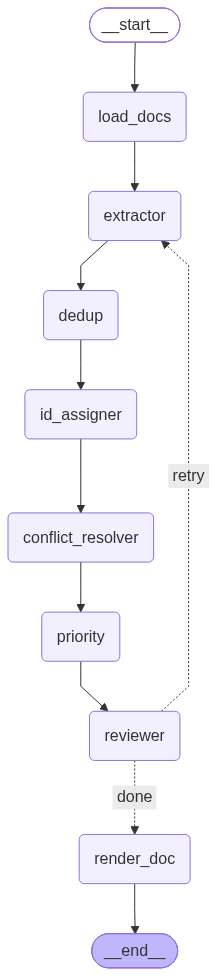

Extracting
Mergining
Resolving conflicts
Assigning priorities
Running reviewer
Review re-run
Extracting
Mergining
Resolving conflicts
Assigning priorities
Running reviewer
Review re-run
Extracting
Mergining
Resolving conflicts
Assigning priorities
Running reviewer
Rendering


In [3]:

structured_llm = ChatOpenAI(model="gpt-4.1-nano").with_structured_output(ExtractionResult)
dedup_llm = ChatOpenAI(model="gpt-5-mini").with_structured_output(DedupResult)
resolver_llm = ChatOpenAI(model="gpt-5.4-nano").with_structured_output(ConflictResult)
reviewer_llm = ChatOpenAI(model="gpt-4o-mini").with_structured_output(ReviewResult)
priority_llm = ChatOpenAI(model="gpt-5-mini").with_structured_output(PriorityResult)


def load_docs(state: State) -> dict: #Deterministic node
    docs = {}
    root = './data/corpus/' #state["input_dir"]
    for path in sorted(glob.glob(os.path.join(root, "**", "*.eml"), recursive=True)):
        if os.path.isfile(path):
            with open(path, encoding="utf-8", errors="replace") as f:
                docs[os.path.relpath(path, root)] = f.read()
    return {'docs':docs}

def extractor(state: State) -> dict:
    print("Extracting")
    todo = state["review_missing"] or {f: [] for f in state["docs"]}
    all_reqs = list(state["raw_reqs"])          # keep what we already have
    for filename, hints in todo.items():
        extra = ("\n\nThe previous pass missed these, make sure they are extracted:\n- " + "\n- ".join(hints)) if hints else ""
        result = structured_llm.invoke([
            ("system", f"""
        Extract every software
        requirement (functional, non-functional, constraint, business rule) that is
        stated or clearly implied in the following document.

        """),
            ("human", f"Document: {filename}\n\n{state['docs'][filename]}{extra}"),
        ])
        for r in result.requirements:
            all_reqs.append({**r.model_dump(), "sources": [filename]})
    return {"raw_reqs": all_reqs}

def dedup(state: State) -> dict:
    print("Mergining")
    raw_reqs = state['raw_reqs']
    all_raw_reqs = ""
    for i, raw_req in enumerate(raw_reqs, start=1):
        all_raw_reqs+=f"{i}. {raw_req['name']}: {raw_req['description']}\n"

    result = dedup_llm.invoke(f"""You receive a numbered list of software requirements extracted
from different documents. Group requirements that are semantically duplicates
(same intent, even if worded differently). Rules:
- Every number must appear in exactly one group.
- Unique requirements go in a group of their own.
- Only group items that truly describe the same thing. Related but different
  requirements (e.g. different limits, different user roles) stay separate.
- For each group, write one merged name and description that keeps all details.
`
{all_raw_reqs}
`
""")
    merged, seen = [], set()
    for g in result.groups:
        ids=[]
        for i in g.ids:
            if 1<=i <= len(raw_reqs) and i not in seen:
                ids.append(i)
        if not ids:
            continue
        seen.update(ids)

        sources = sorted({s for i in ids for s in raw_reqs[i-1]['sources']})
        merged.append({'name': g.name, 'description': g.description, 'sources': sources})

    for i, r in enumerate(raw_reqs, start=1):
        if i not in seen:
            merged.append(r)

    return {'merged_reqs':merged}

def conflict_resolver(state: State) -> dict:
    print("Resolving conflicts")

    reqs = state['merged_reqs']
    all_reqs = "\n".join(f"{r['id']}. {r['name']}: {r['description']}" for r in reqs)
    result = resolver_llm.invoke([("system",f"""
You receive a numbered list of software requirements.
Find requirements that contradict each other (e.g. different limits for the same thing)
or that are nonsensical/unimplementable. For each conflict, keep the better supported
or more recent one and discard the other. Use consistent terminology across requirements.
Only discard when truly necessary. If nothing needs discarding, return an empty list.
    """),
    ('human', all_reqs)])

    by_id = {r['id']: r for r in reqs}
    discarded = {d.id: d for d in result.discards if d.id in by_id}
    kept, blacklist = [], []
    for r in reqs:
        if r['id'] in discarded:
            blacklist.append({
                **r,
                "reason": discarded[r['id']].reason,
                "conflicts_with": discarded[r['id']].conflicts_with,
            })
        else:
            kept.append(r)
    return {"kept_reqs": kept, "blacklist": blacklist}


def reviewer(state: State) -> dict:
    print("Running reviewer")

    final = "\n".join(f"- {r['name']}: {r['description']}" for r in state["kept_reqs"])
    dropped = "\n".join(f"- {r['name']}" for r in state["blacklist"])
    missing = {}   # filename -> list of missing requirement texts
    for filename, text in state["docs"].items():
        res = reviewer_llm.invoke([
            ("system", "List requirements stated in the document that are NOT covered by the "
                       "requirements list. Ignore anything in the discarded list, it was removed on purpose. "
                       "Return an empty list if everything is covered."),
            ("human", f"DOCUMENT {filename}:\n{text}\n\nREQUIREMENTS:\n{final}\n\nDISCARDED:\n{dropped}"),
        ])
        if res.missing:
            missing[filename] = [m.requirement for m in res.missing]
    return {"review_missing": missing, "iterations": state["iterations"] + 1}

def route(state: State) -> str:
    if state["review_missing"] and state["iterations"] < 3:
        print("Review re-run")
        return "retry"
    return "done"

def priority(state:State) -> dict:
    print("Assigning priorities")

    reqs = state["kept_reqs"]
    listing = "\n".join(f"{r['id']}. {r['name']}: {r['description']}" for r in reqs)
    result = priority_llm.invoke([("system",
                                   """You receive a numbered list of software requirements.
Assign each one a priority, judging them relative to each other:
- Top: system is unusable or legally/safety non-compliant without it
- High: core functionality users clearly expect
- Mid: important but a workaround exists
- Low: nice to have, can be postponed
Use the full scale, not everything can be Top. Every number must get exactly one priority."""
                                   ), ("human", listing)])

    by_id = {r['id']: r for r in reqs}
    by_num = {p.id: p for p in result.priorities if p.id in by_id}
    out = []
    for r in reqs:
        p = by_num.get(r['id'])
        out.append({**r,
                    "priority": p.priority if p else "Mid",   # safety net for skipped items
                    "priority_reason": p.justification if p else "Not rated by model, default"})
    return {"kept_reqs": out}

def id_assigner(state: State) -> dict:
    reqs = state['merged_reqs']
    for i, r in enumerate(reqs, 1):
        r['id'] = i
    return {"merged_reqs": reqs}

def render_doc(state: State) -> dict:
    print("Rendering")
    lines = [
        "# Technical Requirements",
        "",
        "Below are the technical requirements selected for implementation.",
        "",
    ]
    for index, requirement in enumerate(state["kept_reqs"], 1):
        lines.extend([
            f"## {requirement.get('name', 'Unnamed requirement')}",
            f"ID: {requirement['id']}",
            f"Priority: {requirement.get('priority', 'Not assigned')}",
            "",
            requirement.get("description", ""),
            "",
            "Sources:",
        ])
        lines.extend(f"- {source}" for source in requirement.get("sources", []))
        lines.extend(["", "---", ""])

    lines.extend([
        "# Blacklist",
        "",
        "Below are blacklisted requirements and the reasons they were discarded.",
        "",
    ])
    for index, requirement in enumerate(state["blacklist"], 1):
        lines.extend([
            f"## {requirement.get('name', 'Unnamed requirement')}",
            f"ID: {requirement['id']}",
            f"Reason: {requirement.get('reason', 'No reason provided')}",
            f"Conflicts with: {', '.join(map(str, requirement.get('conflicts_with', []))) or 'None'}",
            "",
        ])

    with open("requirements.md", "w", encoding="utf-8") as file:
        file.write("\n".join(lines).rstrip() + "\n")
    return {}

g = StateGraph(State)
g.add_node('load_docs', load_docs)
g.add_node('extractor', extractor)
g.add_node('dedup', dedup)
g.add_node('conflict_resolver', conflict_resolver)
g.add_node('reviewer', reviewer)
g.add_node('priority', priority)
g.add_node('id_assigner', id_assigner)
g.add_node('render_doc', render_doc)

g.add_edge(START, 'load_docs')
g.add_edge('load_docs', 'extractor')
g.add_edge('extractor', 'dedup')
g.add_edge('dedup', 'id_assigner')
g.add_edge('id_assigner', 'conflict_resolver')
g.add_edge('conflict_resolver', 'priority')
g.add_edge('priority', 'reviewer')
g.add_conditional_edges("reviewer", route, {"retry": "extractor", "done": "render_doc"})
g.add_edge("render_doc", END)
app = g.compile()
display(Image(app.get_graph().draw_mermaid_png()))
out = app.invoke({'docs':{}, 'raw_reqs':[], 'blacklist': [], 'kept_reqs': [], 'review_missing': {}, 'iterations': 0})


In [ ]:
out = app.invoke({'input_dir'})

In [ ]:
with open(files[1], 'r') as f:
    print(f.read())